# v2 Notebook 04: Results

**Author:** Anush Jindal

Reads the scores saved by notebook 03 (no training here, so it runs in seconds) and answers
three questions:

1. **How good are the trees really?** The same full-size trees under the four tests.
2. **Which attacks are caught when the tree has never seen them?**
3. **What does shrinking the tree cost**, now that it is measured on unseen traffic?

Words used below:

| Word | Meaning |
|---|---|
| **Seen attack** | An attack type that was in the training data (the test flows themselves are always new). |
| **Unseen attack** | An attack type that was kept out of training completely. |
| **Recall** | Of the attack flows in the test set, the share the tree flagged as an attack. |
| **Recall per attack type** | Recall worked out for each attack type separately and then averaged, so a rare attack counts as much as a common one. |
| **False-alarm rate** | Share of normal flows flagged as an attack. |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))  # finds helpers.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import helpers as h

trees = pd.read_csv(h.RESULTS_DIR / "03_all_trees.csv", dtype={"setting": str})
per_attack = pd.read_csv(h.RESULTS_DIR / "03_recall_per_attack.csv", dtype={"setting": str})
LISTS = list(trees["feature_list"].unique())
TESTS = list(trees["test"].unique())
DEPTH_ORDER = ["1", "2", "3", "4", "5", "6", "8", "10", "12", "15", "20", "none"]
COLOURS = {"1 random split": "#9aa5b1", "2 later traffic": "#1f5fa8", "3 new attack": "#d1495b", "4 new day": "#e09f3e"}
print(f"{len(trees):,} tree sizes scored; runs per test:")
print(trees.groupby("test", sort=False)["held_out"].nunique().to_string())

2,016 tree sizes scored; runs per test:
test
1 random split      1
2 later traffic     1
3 new attack       14
4 new day           5


## 1. How good are the trees really?

The full-size trees (no depth limit, no pruning) under each test. Tests 3 and 4 have several
runs (one per attack type, one per day); their numbers are averages over those runs.

In [2]:
full = trees[(trees["method"] == "depth limit") & (trees["setting"] == "none")]

def pooled(rows_col, recall_col):
    """Recall over all flows of all runs together (NaN when there are no such flows)."""
    def f(g):
        rows = g[rows_col].sum()
        return (g[rows_col] * g[recall_col]).sum() / rows if rows else np.nan
    return f

groups = full.groupby(["test", "feature_list"], sort=False)
summary = groups.agg(runs=("held_out", "nunique"), nodes=("nodes", "mean"), compact_kb=("compact_kb", "mean"),
                     false_alarm_rate=("false_alarm_rate", "mean"))
summary["seen_recall_all_flows"] = groups.apply(pooled("seen_attack_rows", "seen_attack_recall"), include_groups=False)
summary["seen_recall_per_attack_type"] = groups["seen_recall_per_attack_mean"].mean()
summary["unseen_recall_all_flows"] = groups.apply(pooled("unseen_attack_rows", "unseen_attack_recall"), include_groups=False)
summary["unseen_recall_per_attack_type"] = groups["unseen_recall_per_attack_mean"].mean()
summary = summary.reset_index()
summary.round(4).to_csv(h.RESULTS_DIR / "04_summary_by_test.csv", index=False)

show = summary.copy()
rate_cols = ["false_alarm_rate", "seen_recall_all_flows", "seen_recall_per_attack_type", "unseen_recall_all_flows", "unseen_recall_per_attack_type"]
show[rate_cols] = (show[rate_cols] * 100).round(2)
show[["nodes", "compact_kb"]] = show[["nodes", "compact_kb"]].round(1)
show.set_index(["test", "feature_list"])

runs    nodes  compact_kb  false_alarm_rate  \
test            feature_list                                                
1 random split  A-NS             1   5493.0        48.3              0.11   
                B-NS             1   6659.0        58.5              0.14   
                C-NS             1   8303.0        73.0              0.16   
                D-NS             1  24277.0       213.4              0.49   
2 later traffic A-NS             1   4043.0        35.5              0.08   
                B-NS             1   5045.0        44.3              0.09   
                C-NS             1   5699.0        50.1              0.16   
                D-NS             1  24897.0       218.8              0.24   
3 new attack    A-NS            14   3826.7        33.6              0.07   
                B-NS            14   4765.7        41.9              0.09   
                C-NS            14   5343.3        47.0              0.14   
                D-NS            14  23202.4       203.9              0.22   
4 new day       A-NS             5   3218.6        28.3              1.18   
                B-NS             5   3913.8        34.4              1.77   
                C-NS             5   4293.8        37.7              0.21   
                D-NS             5  19428.2       170.8              0.88   

                              seen_recall_all_flows  \
test            feature_list                          
1 random split  A-NS                          99.17   
                B-NS                          99.07   
                C-NS                          98.93   
                D-NS                          97.36   
2 later traffic A-NS                          94.69   
                B-NS                          94.91   
                C-NS                          93.41   
                D-NS                          90.15   
3 new attack    A-NS                          94.90   
                B-NS                          94.54   
                C-NS                          93.70   
                D-NS                          89.57   
4 new day       A-NS                            NaN   
                B-NS                            NaN   
                C-NS                            NaN   
                D-NS                            NaN   

                              seen_recall_per_attack_type  \
test            feature_list                                
1 random split  A-NS                                85.95   
                B-NS                                86.85   
                C-NS                                83.05   
                D-NS                                72.22   
2 later traffic A-NS                                82.28   
                B-NS                                75.82   
                C-NS                                70.83   
                D-NS                                59.55   
3 new attack    A-NS                                81.67   
                B-NS                                77.32   
                C-NS                                71.56   
                D-NS                                59.10   
4 new day       A-NS                                  NaN   
                B-NS                                  NaN   
                C-NS                                  NaN   
                D-NS                                  NaN   

                              unseen_recall_all_flows  \
test            feature_list                            
1 random split  A-NS                              NaN   
                B-NS                              NaN   
                C-NS                              NaN   
                D-NS                              NaN   
2 later traffic A-NS                              NaN   
                B-NS                              NaN   
                C-NS                              NaN   
                D-NS                    

Each recall is given twice. **All flows** counts every attack flow equally, so the three
biggest attacks (DoS Hulk, DDoS, PortScan: 92% of all attack flows) decide it; this is the
number v1 reported. **Per attack type** works out recall for each attack type and averages
them, so every type counts equally. "Seen" and "unseen" say whether the attack type was in
the training data.

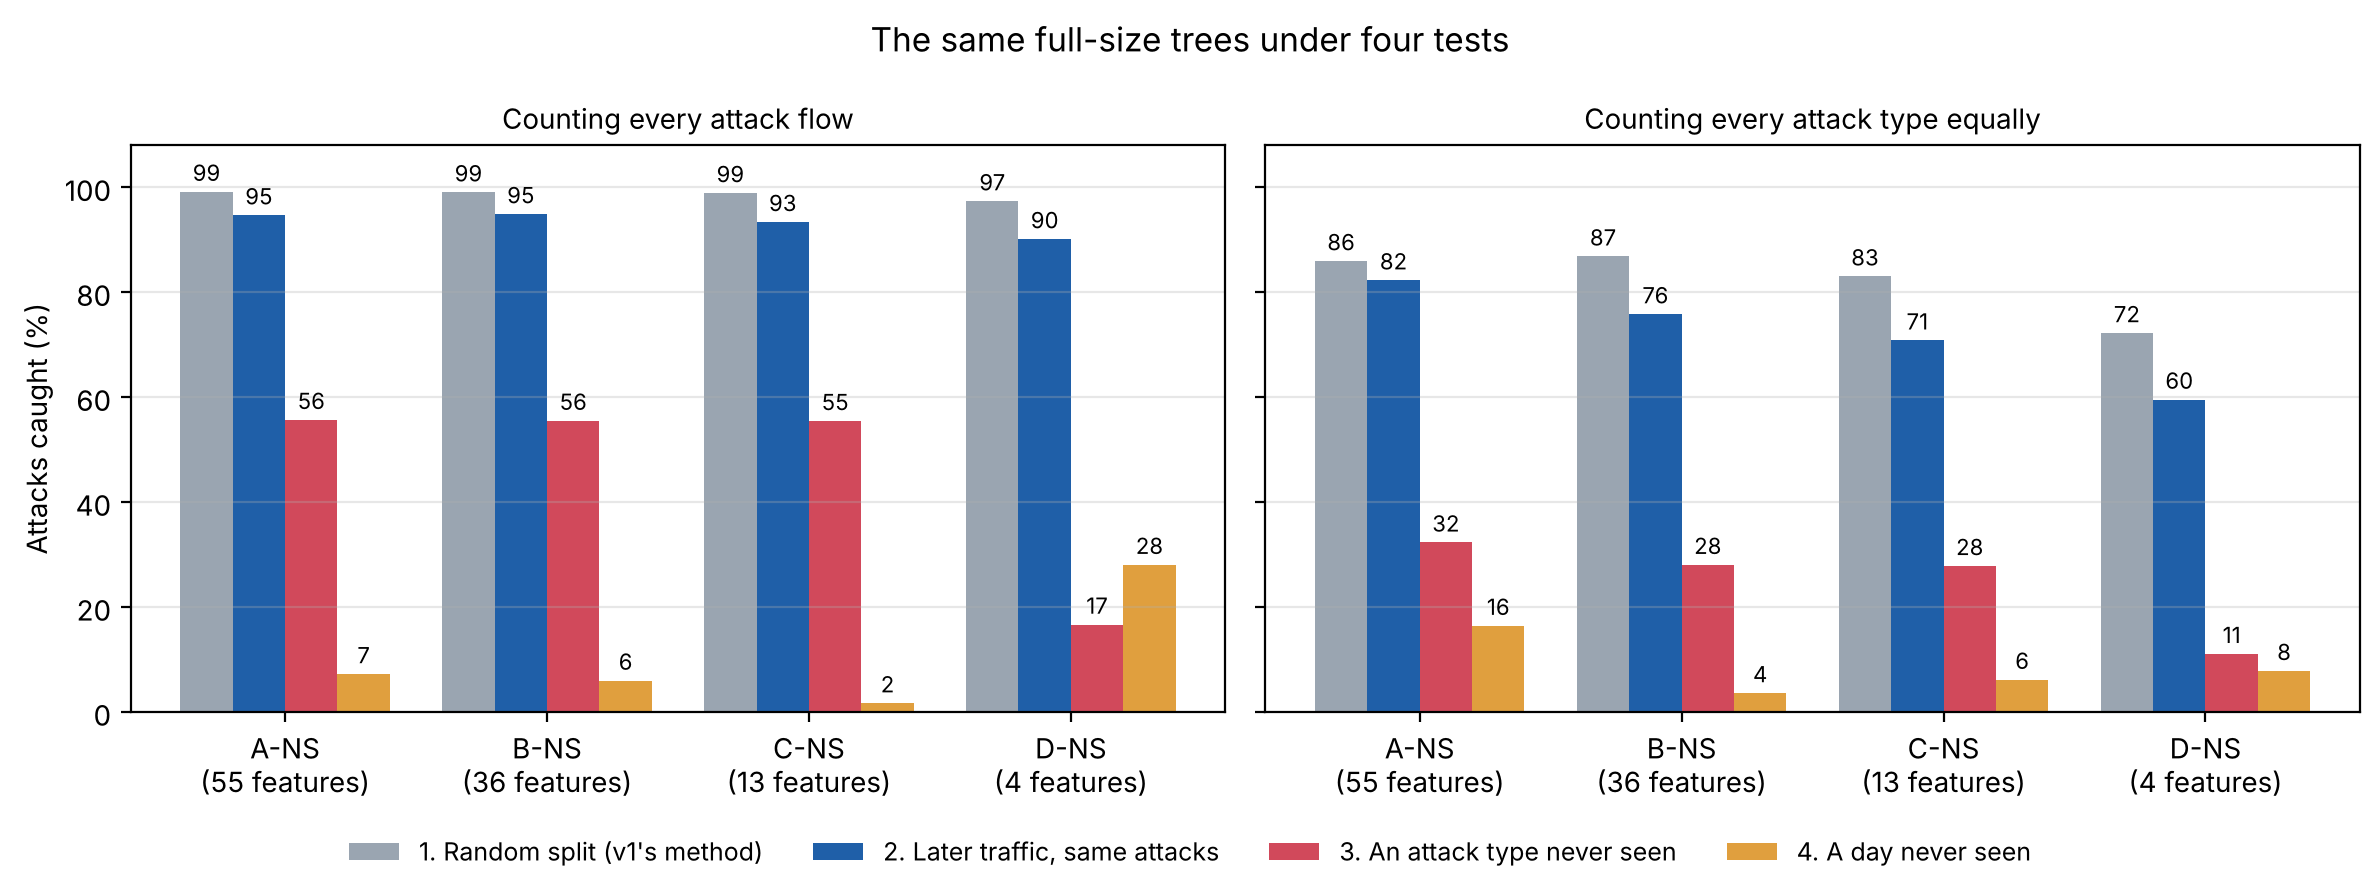

In [3]:
LABELS = {"1 random split": "1. Random split (v1's method)", "2 later traffic": "2. Later traffic, same attacks",
          "3 new attack": "3. An attack type never seen", "4 new day": "4. A day never seen"}
PANELS = [("Counting every attack flow", "recall_all_flows"), ("Counting every attack type equally", "recall_per_attack_type")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
x = np.arange(len(LISTS)); w = 0.2
for ax, (title, col) in zip(axes, PANELS):
    for i, test in enumerate(TESTS):
        kind = "seen" if test in ("1 random split", "2 later traffic") else "unseen"
        values = summary[summary["test"] == test].set_index("feature_list").loc[LISTS, f"{kind}_{col}"] * 100
        b = ax.bar(x + (i - 1.5) * w, values, w, label=LABELS[test], color=COLOURS[test])
        ax.bar_label(b, fmt="%.0f", fontsize=8, padding=2)
    ax.set_xticks(x); ax.set_xticklabels([f"{l}\n({trees[trees.feature_list == l].features.iloc[0]} features)" for l in LISTS])
    ax.set_title(title, fontsize=10); ax.set_ylim(0, 108); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Attacks caught (%)")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, ncol=4, fontsize=9, loc="lower center", frameon=False)
fig.suptitle("The same full-size trees under four tests")
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(h.FIG_DIR / "fig2_four_tests.png", dpi=200); plt.show()

### Test 4 day by day

Each row is a tree that never saw that day. Monday has no attacks, so it only tests false
alarms on a new day of normal traffic. For comparison, the false-alarm rate on later traffic
from days the tree *has* seen (test 2) is 0.08% to 0.24%.

In [4]:
days = full[full["test"] == "4 new day"].pivot(index="held_out", columns="feature_list")
day_table = pd.concat({"false-alarm rate (%)": days["false_alarm_rate"][LISTS] * 100,
                       "that day's attack types caught (%)": days["unseen_recall_per_attack_mean"][LISTS] * 100}, axis=1)
day_table.loc[h.DAYS].round(2)

false-alarm rate (%)                    \
feature_list                 A-NS  B-NS  C-NS  D-NS   
held_out                                              
Monday                       0.10  0.17  0.20  0.52   
Tuesday                      0.26  0.49  0.32  0.60   
Wednesday                    0.04  0.08  0.07  0.44   
Thursday                     3.38  7.72  0.32  0.70   
Friday                       2.14  0.37  0.17  2.14   

             that day's attack types caught (%)                      
feature_list                               A-NS  B-NS   C-NS   D-NS  
held_out                                                             
Monday                                      NaN   NaN    NaN    NaN  
Tuesday                                    0.36  0.32  15.69   0.17  
Wednesday                                 18.90  8.02   6.33  16.46  
Thursday                                  46.49  5.99   2.57   2.52  
Friday                                     0.02  0.07   0.02  12.20

## 2. Which attacks are caught when the tree has never seen them?

For each attack type, the full-size tree's recall

- when the attack **was** in training (test 2, later traffic), and
- when it was **kept out** of training (test 3, new attack).

In [5]:
pa = per_attack[(per_attack["method"] == "depth limit") & (per_attack["setting"] == "none")
                & (per_attack["scored_on"] == "test")]
seen = pa[pa["test"] == "2 later traffic"].pivot(index="attack", columns="feature_list", values="recall")[LISTS]
unseen = (pa[(pa["test"] == "3 new attack") & (~pa["seen_in_training"])]
          .pivot(index="attack", columns="feature_list", values="recall")[LISTS])
rows = pa[(pa["test"] == "3 new attack") & (~pa["seen_in_training"]) & (pa["feature_list"] == LISTS[0])].set_index("attack")["rows"]

by_attack = pd.concat({"flows": rows.to_frame("total"), "recall when seen (%)": seen * 100,
                       "recall when unseen (%)": unseen * 100}, axis=1).sort_values(("flows", "total"), ascending=False)
flat = by_attack.copy(); flat.columns = [" ".join(c) for c in flat.columns]
flat.reset_index().round(2).to_csv(h.RESULTS_DIR / "04_recall_by_attack.csv", index=False)
by_attack.round(1)

flows recall when seen (%)                     \
                             total                 A-NS   B-NS  C-NS  D-NS   
attack                                                                       
DoS Hulk                    172846                 89.8   90.5  86.7  81.5   
DDoS                        128014                 99.6   99.7  99.6  98.8   
PortScan                     90694                 99.8   99.8  99.6  99.3   
DoS GoldenEye                10286                 99.8   99.9  99.1  94.2   
FTP-Patator                   5931                 97.2   97.4  98.4  96.1   
DoS slowloris                 5385                 76.9   73.9  83.6  68.9   
DoS Slowhttptest              5228                 93.3   95.5  92.8  78.5   
SSH-Patator                   3219                 87.2   87.4  85.5  89.6   
Bot                           1948                  0.0    0.0   0.0   0.0   
Web Attack - Brute Force      1470                 94.6   81.6  86.7  20.1   
Web Attack - XSS               652                 92.3   82.3  84.6   6.9   
Infiltration                    36                 71.4   28.6   0.0   0.0   
Web Attack - Sql Injection      21                 50.0   25.0  25.0  50.0   
Heartbleed                      11                100.0  100.0  50.0  50.0   

                           recall when unseen (%)                    
                                             A-NS  B-NS  C-NS  D-NS  
attack                                                               
DoS Hulk                                     85.8  85.8  85.1   9.7  
DDoS                                         63.0  63.3  63.1  34.9  
PortScan                                      0.2   0.3   0.3   4.4  
DoS GoldenEye                                 3.4   3.8  31.8  13.4  
FTP-Patator                                   0.0   0.0   0.0   0.7  
DoS slowloris                                70.9  73.4  53.6  68.1  
DoS Slowhttptest                             36.6  25.5   7.6   5.5  
SSH-Patator                                   0.1   0.5   0.4   0.2  
Bot                                           0.0   0.0   0.0   0.0  
Web Attack - Brute Force                     82.5  48.9  59.2   5.3  
Web Attack - XSS                             92.9  73.5  83.9   5.4  
Infiltration                                  2.8   8.3   0.0   2.8  
Web Attack - Sql Injection                   14.3   9.5   4.8   4.8  
Heartbleed                                    0.0   0.0   0.0   0.0

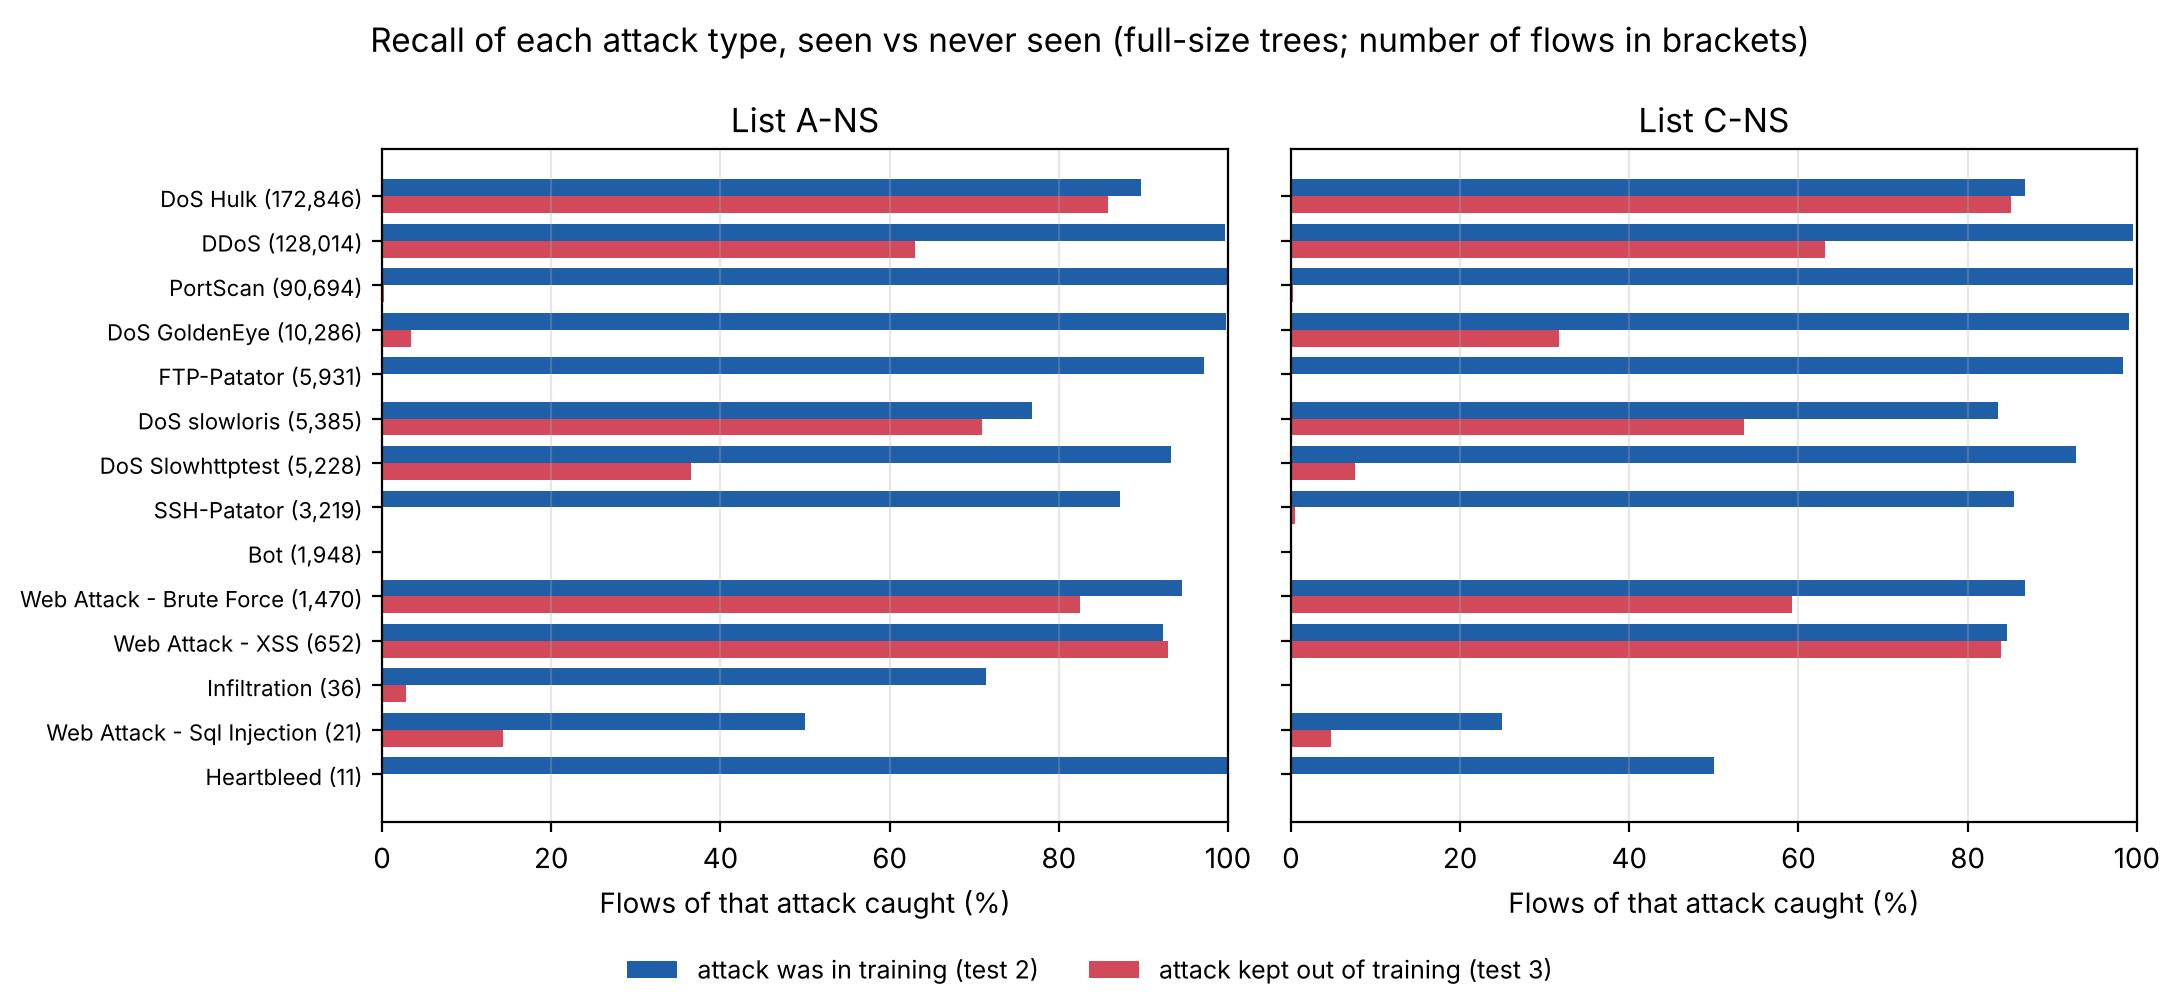

In [6]:
order = by_attack.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, l in zip(axes, [LISTS[0], LISTS[2]]):
    y = np.arange(len(order)); hgt = 0.38
    ax.barh(y + hgt / 2, seen.loc[order, l] * 100, hgt, label="attack was in training (test 2)", color=COLOURS["2 later traffic"])
    ax.barh(y - hgt / 2, unseen.loc[order, l] * 100, hgt, label="attack kept out of training (test 3)", color=COLOURS["3 new attack"])
    ax.set_yticks(y); ax.set_yticklabels([f"{a} ({rows[a]:,})" for a in order], fontsize=8)
    ax.set_xlabel("Flows of that attack caught (%)"); ax.set_xlim(0, 100); ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"List {l}")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, ncol=2, fontsize=9, loc="lower center", frameon=False)
fig.suptitle("Recall of each attack type, seen vs never seen (full-size trees; number of flows in brackets)")
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(h.FIG_DIR / "fig3_seen_vs_unseen_by_attack.png", dpi=200); plt.show()

## 3. What does shrinking the tree cost?

### 3a. Detection at every depth

The same curves v1 drew, but once for each test. Lines show the average over the runs of a
test.

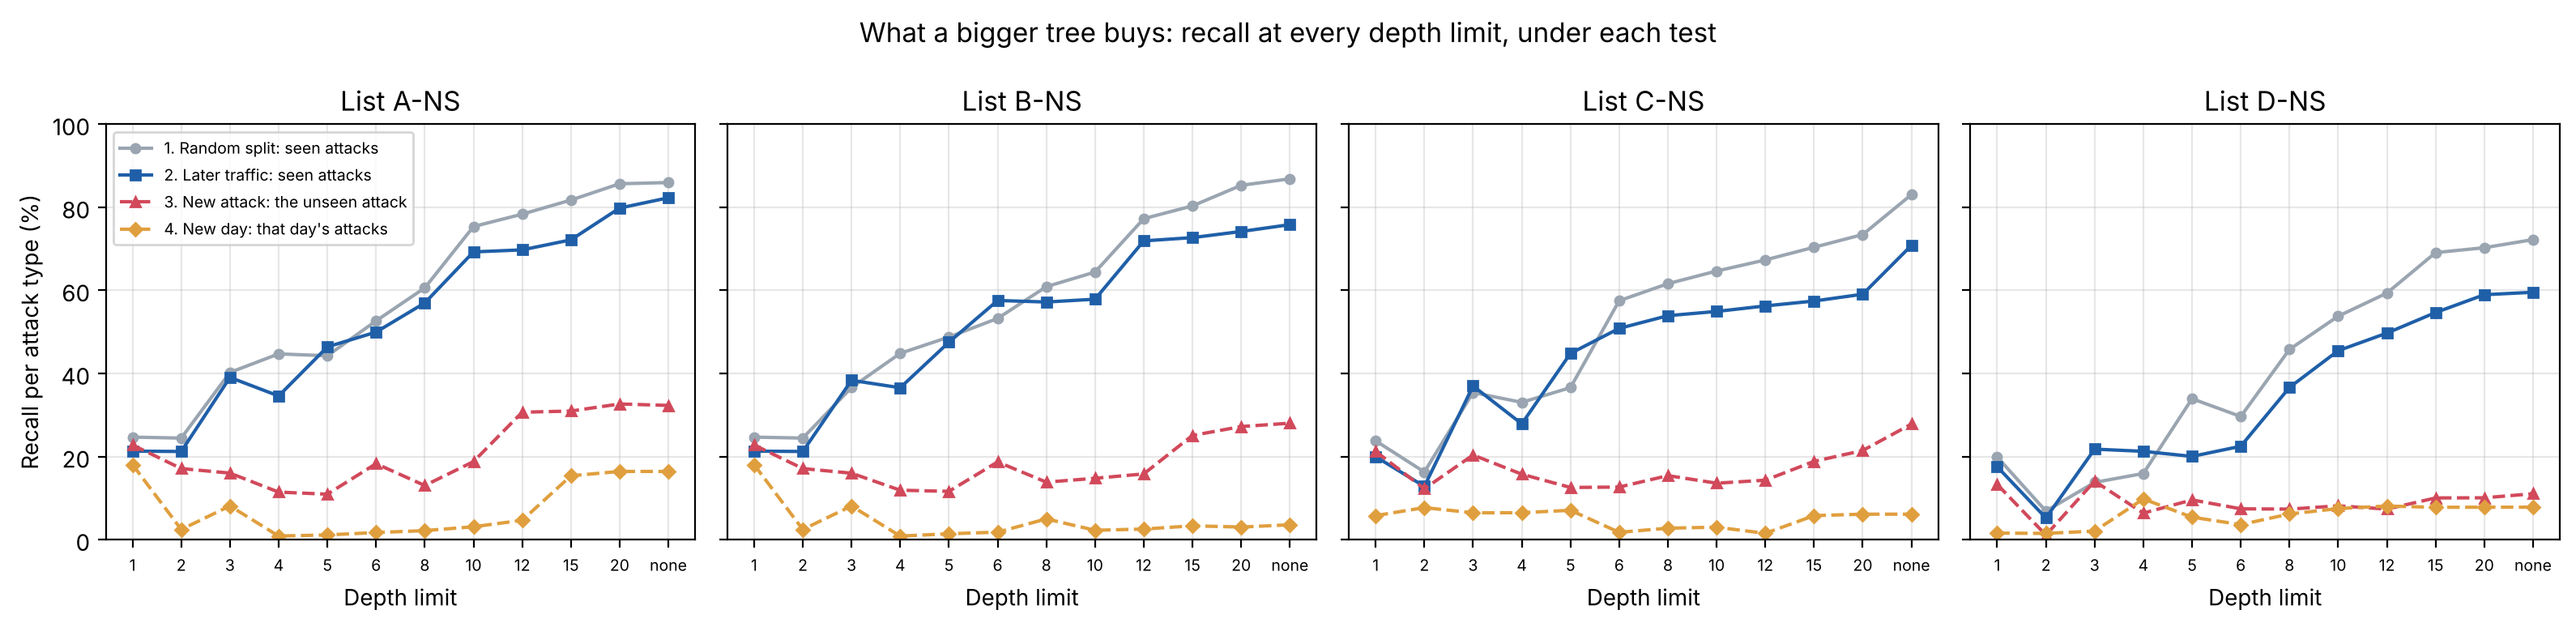

In [7]:
depth = trees[trees["method"] == "depth limit"]
curves = (depth.groupby(["test", "feature_list", "setting"], sort=False)
          .agg(nodes=("nodes", "mean"), false_alarm_rate=("false_alarm_rate", "mean"),
               seen_recall_per_attack_type=("seen_recall_per_attack_mean", "mean"),
               unseen_recall_per_attack_type=("unseen_recall_per_attack_mean", "mean")).reset_index())

LINES = [("1 random split", "seen_recall_per_attack_type", "1. Random split: seen attacks", "o", "-"),
         ("2 later traffic", "seen_recall_per_attack_type", "2. Later traffic: seen attacks", "s", "-"),
         ("3 new attack", "unseen_recall_per_attack_type", "3. New attack: the unseen attack", "^", "--"),
         ("4 new day", "unseen_recall_per_attack_type", "4. New day: that day's attacks", "D", "--")]
fig, axes = plt.subplots(1, len(LISTS), figsize=(4 * len(LISTS), 3.9), sharey=True)
for ax, l in zip(axes, LISTS):
    for test, col, label, marker, style in LINES:
        c = curves[(curves["test"] == test) & (curves["feature_list"] == l)].set_index("setting").loc[DEPTH_ORDER]
        ax.plot(range(len(DEPTH_ORDER)), c[col] * 100, marker=marker, ms=4, ls=style, color=COLOURS[test], label=label)
    ax.set_xticks(range(len(DEPTH_ORDER))); ax.set_xticklabels(DEPTH_ORDER, fontsize=7)
    ax.set_xlabel("Depth limit"); ax.set_title(f"List {l}"); ax.grid(alpha=0.3); ax.set_ylim(0, 100)
axes[0].set_ylabel("Recall per attack type (%)")
axes[0].legend(fontsize=7, loc="upper left")
fig.suptitle("What a bigger tree buys: recall at every depth limit, under each test")
fig.tight_layout(); fig.savefig(h.FIG_DIR / "fig4_recall_vs_depth.png", dpi=200); plt.show()

In [8]:
# The numbers behind the figure, for the first feature list
l = LISTS[0]
table = pd.DataFrame({"nodes (test 2)": curves[(curves.test == "2 later traffic") & (curves.feature_list == l)].set_index("setting")["nodes"]})
for test, col, label, *_ in LINES:
    table[label] = curves[(curves.test == test) & (curves.feature_list == l)].set_index("setting")[col] * 100
table["false alarms, test 2 (%)"] = curves[(curves.test == "2 later traffic") & (curves.feature_list == l)].set_index("setting")["false_alarm_rate"] * 100
print("List", l)
table.loc[DEPTH_ORDER].round(2)

List A-NS


,nodes (test 2),1. Random split: seen attacks,2. Later traffic: seen attacks,3. New attack: the unseen attack,4. New day: that day's attacks,"false alarms, test 2 (%)"
setting,,,,,,
1,3.0,24.70,21.32,22.81,18.09,0.04
2,7.0,24.46,21.24,17.13,2.47,0.01
3,15.0,40.27,39.07,16.04,8.14,2.53
4,31.0,44.73,34.60,11.46,0.89,0.92
5,57.0,44.28,46.41,10.97,1.17,0.43
6,89.0,52.67,49.97,18.31,1.73,0.50
8,175.0,60.61,56.99,13.05,2.20,0.10
10,279.0,75.37,69.27,18.81,3.13,0.10
12,409.0,78.35,69.75,30.69,4.69,0.05


### 3b. The smallest good tree, chosen on validation data

As in v1, the size is chosen on the **validation** rows, never on the test rows. The rule
(fixed before looking at the test scores):

> Take the smallest tree for which, on the validation rows,
> - every attack type with at least 100 validation flows keeps its recall within
>   **1 percentage point** of the full-size tree, and
> - the false-alarm rate is at most **0.1 percentage points** higher than the full-size tree's.

The rule is applied separately to depth limits and to pruning. In tests 3 and 4 the
validation rows contain only attacks the tree has seen, because nobody can validate on an
attack they do not know about.

In [9]:
MIN_VALIDATION_ROWS, RECALL_TOLERANCE, FALSE_ALARM_TOLERANCE = 100, 0.01, 0.001
KEYS = ["test", "held_out", "feature_list"]

val = per_attack[(per_attack["scored_on"] == "validation") & (per_attack["rows"] >= MIN_VALIDATION_ROWS)]
val_full = (val[(val["method"] == "depth limit") & (val["setting"] == "none")]
            .set_index(KEYS + ["attack"])["recall"].rename("full_recall"))
val = val.join(val_full, on=KEYS + ["attack"])
val["drop"] = val["full_recall"] - val["recall"]
worst_drop = val.groupby(KEYS + ["method", "setting"])["drop"].max().rename("worst_validation_drop")

cand = trees.join(worst_drop, on=KEYS + ["method", "setting"])
full_far = full.set_index(KEYS)["val_false_alarm_rate"].rename("full_val_far")
cand = cand.join(full_far, on=KEYS)
ok = cand[(cand["worst_validation_drop"] <= RECALL_TOLERANCE)
          & (cand["val_false_alarm_rate"] <= cand["full_val_far"] + FALSE_ALARM_TOLERANCE)]
chosen = ok.sort_values("nodes").groupby(KEYS + ["method"], sort=False).head(1)

# Put each chosen tree next to the full-size tree of the same run
score_cols = ["nodes", "compact_kb", "avg_comparisons", "false_alarm_rate", "seen_attack_recall",
              "seen_recall_per_attack_mean", "unseen_recall_per_attack_mean"]
side = chosen.set_index(KEYS + ["method"])[["setting"] + score_cols].join(
    full.set_index(KEYS)[score_cols].add_prefix("full_"), on=KEYS).reset_index()
side["nodes_removed_pct"] = 100 * (1 - side["nodes"] / side["full_nodes"])

chosen_summary = (side.groupby(["test", "feature_list", "method"], sort=False)
                  .agg(runs=("held_out", "nunique"),
                       typical_setting=("setting", lambda s: s.mode().iloc[0]),
                       nodes_full=("full_nodes", "mean"), nodes_chosen=("nodes", "mean"),
                       nodes_removed_pct=("nodes_removed_pct", "mean"),
                       compact_kb_full=("full_compact_kb", "mean"), compact_kb_chosen=("compact_kb", "mean"),
                       comparisons_full=("full_avg_comparisons", "mean"), comparisons_chosen=("avg_comparisons", "mean"),
                       false_alarm_full=("full_false_alarm_rate", "mean"), false_alarm_chosen=("false_alarm_rate", "mean"),
                       seen_recall_full=("full_seen_attack_recall", "mean"), seen_recall_chosen=("seen_attack_recall", "mean"),
                       seen_per_type_full=("full_seen_recall_per_attack_mean", "mean"), seen_per_type_chosen=("seen_recall_per_attack_mean", "mean"),
                       unseen_recall_full=("full_unseen_recall_per_attack_mean", "mean"), unseen_recall_chosen=("unseen_recall_per_attack_mean", "mean"))
                  .reset_index())
chosen_summary["feature_list"] = pd.Categorical(chosen_summary["feature_list"], LISTS)
chosen_summary = chosen_summary.sort_values(["test", "feature_list", "method"]).reset_index(drop=True)
chosen_summary.round(4).to_csv(h.RESULTS_DIR / "04_chosen_trees.csv", index=False)

show = chosen_summary.copy()
pct_cols = [c for c in show.columns if "false_alarm" in c or "recall" in c or "per_type" in c]
show[pct_cols] = (show[pct_cols] * 100).round(2)
show = show.round({"nodes_full": 0, "nodes_chosen": 0, "nodes_removed_pct": 0, "compact_kb_full": 1, "compact_kb_chosen": 1,
                   "comparisons_full": 1, "comparisons_chosen": 1})
cols = ["feature_list", "method", "typical_setting", "nodes_full", "nodes_chosen", "nodes_removed_pct", "compact_kb_chosen",
        "comparisons_full", "comparisons_chosen", "seen_recall_full", "seen_recall_chosen",
        "seen_per_type_full", "seen_per_type_chosen", "false_alarm_full", "false_alarm_chosen"]
print("Test 2, later traffic ('none' = no depth limit met the rule, so the full tree is kept)")
show.loc[show["test"] == "2 later traffic", cols].set_index(["feature_list", "method"])

Test 2, later traffic ('none' = no depth limit met the rule, so the full tree is kept)


typical_setting  nodes_full  nodes_chosen  \
feature_list method                                                  
A-NS         depth limit            none      4043.0        4043.0   
             pruning               1e-06      4043.0         913.0   
B-NS         depth limit            none      5045.0        5045.0   
             pruning               3e-07      5045.0        2841.0   
C-NS         depth limit            none      5699.0        5699.0   
             pruning               1e-06      5699.0        1475.0   
D-NS         depth limit            none     24897.0       24897.0   
             pruning               3e-07     24897.0       22191.0   

                          nodes_removed_pct  compact_kb_chosen  \
feature_list method                                              
A-NS         depth limit                0.0               35.5   
             pruning                   77.0                8.0   
B-NS         depth limit                0.0               44.3   
             pruning                   44.0               25.0   
C-NS         depth limit                0.0               50.1   
             pruning                   74.0               13.0   
D-NS         depth limit                0.0              218.8   
             pruning                   11.0              195.0   

                          comparisons_full  comparisons_chosen  \
feature_list method                                              
A-NS         depth limit              17.6                17.6   
             pruning                  17.6                14.7   
B-NS         depth limit              15.5                15.5   
             pruning                  15.5                14.4   
C-NS         depth limit              15.5                15.5   
             pruning                  15.5                12.4   
D-NS         depth limit              14.7                14.7   
             pruning                  14.7                13.5   

                          seen_recall_full  seen_recall_chosen  \
feature_list method                                              
A-NS         depth limit             94.69               94.69   
             pruning                 94.69               94.72   
B-NS         depth limit             94.91               94.91   
             pruning                 94.91               94.91   
C-NS         depth limit             93.41               93.41   
             pruning                 93.41               93.26   
D-NS         depth limit             90.15               90.15   
             pruning                 90.15               90.21   

                          seen_per_type_full  seen_per_type_chosen  \
feature_list method                                                  
A-NS         depth limit               82.28                 82.28   
             pruning                   82.28                 80.21   
B-NS         depth limit               75.82                 75.82   
             pruning                   75.82                 75.82   
C-NS         depth limit               70.83                 70.83   
             pruning                   70.83                 70.99   
D-NS         depth limit               59.55                 59.55   
             pruning                   59.55                 59.57   

                          false_alarm_full  false_alarm_chosen  
feature_list method                                             
A-NS         depth limit              0.08                0.08  
             pruning                  0.08                0.07  
B-NS         depth limit              0.09                0.09  
             pruning                  0.09                0.10  
C-NS         depth limit              0.16                0.16  
             pruning                  0.16                0.13  
D-NS         depth limit              0.24                0.24  
             pruning                  0.24             

The same choice in the tests with unseen attacks (averages over the runs of each test):

In [10]:
cols = ["test", "feature_list", "method", "nodes_full", "nodes_chosen", "nodes_removed_pct", "false_alarm_full",
        "false_alarm_chosen", "seen_per_type_full", "seen_per_type_chosen", "unseen_recall_full", "unseen_recall_chosen"]
show.loc[show["test"].isin(["3 new attack", "4 new day"]), cols].set_index(["test", "feature_list", "method"])

nodes_full  nodes_chosen  \
test         feature_list method                                  
3 new attack A-NS         depth limit      3827.0        3195.0   
                          pruning          3827.0        1087.0   
             B-NS         depth limit      4766.0        4766.0   
                          pruning          4766.0        2388.0   
             C-NS         depth limit      5343.0        5343.0   
                          pruning          5343.0        1796.0   
             D-NS         depth limit     23202.0       23202.0   
                          pruning         23202.0       20664.0   
4 new day    A-NS         depth limit      3219.0        2348.0   
                          pruning          3219.0         854.0   
             B-NS         depth limit      3914.0        3533.0   
                          pruning          3914.0        1348.0   
             C-NS         depth limit      4294.0        3903.0   
                          pruning          4294.0        1469.0   
             D-NS         depth limit     19428.0       16250.0   
                          pruning         19428.0       15121.0   

                                       nodes_removed_pct  false_alarm_full  \
test         feature_list method                                             
3 new attack A-NS         depth limit               17.0              0.07   
                          pruning                   71.0              0.07   
             B-NS         depth limit                0.0              0.09   
                          pruning                   50.0              0.09   
             C-NS         depth limit                0.0              0.14   
                          pruning                   66.0              0.14   
             D-NS         depth limit                0.0              0.22   
                          pruning                   11.0              0.22   
4 new day    A-NS         depth limit               29.0              1.18   
                          pruning                   73.0              1.18   
             B-NS         depth limit               10.0              1.77   
                          pruning                   66.0              1.77   
             C-NS         depth limit                9.0              0.21   
                          pruning                   67.0              0.21   
             D-NS         depth limit               16.0              0.88   
                          pruning                   22.0              0.88   

                                       false_alarm_chosen  seen_per_type_full  \
test         feature_list method                                                
3 new attack A-NS         depth limit                0.07               81.67   
                          pruning                    0.06               81.67   
             B-NS         depth limit                0.09               77.32   
                          pruning                    0.09               77.32   
             C-NS         depth limit                0.14               71.56   
                          pruning                    0.13               71.56   
             D-NS         depth limit                0.22               59.10   
                          pruning                    0.23               59.10   
4 new day    A-NS         depth limit                1.19                 NaN   
                          pruning                    1.17                 NaN   
             B-NS         depth limit                1.77                 NaN   
                          pruning                    1.76                 NaN   
             C-NS         depth limit                0.21                 NaN   
                          pruning                    0.19                 NaN   
             D-NS         depth limit                0.81                 NaN   
                          pruning                 

### 3c. Depth limits compared with pruning

Recall per attack type against tree size (test 2, later traffic) for both ways of shrinking.

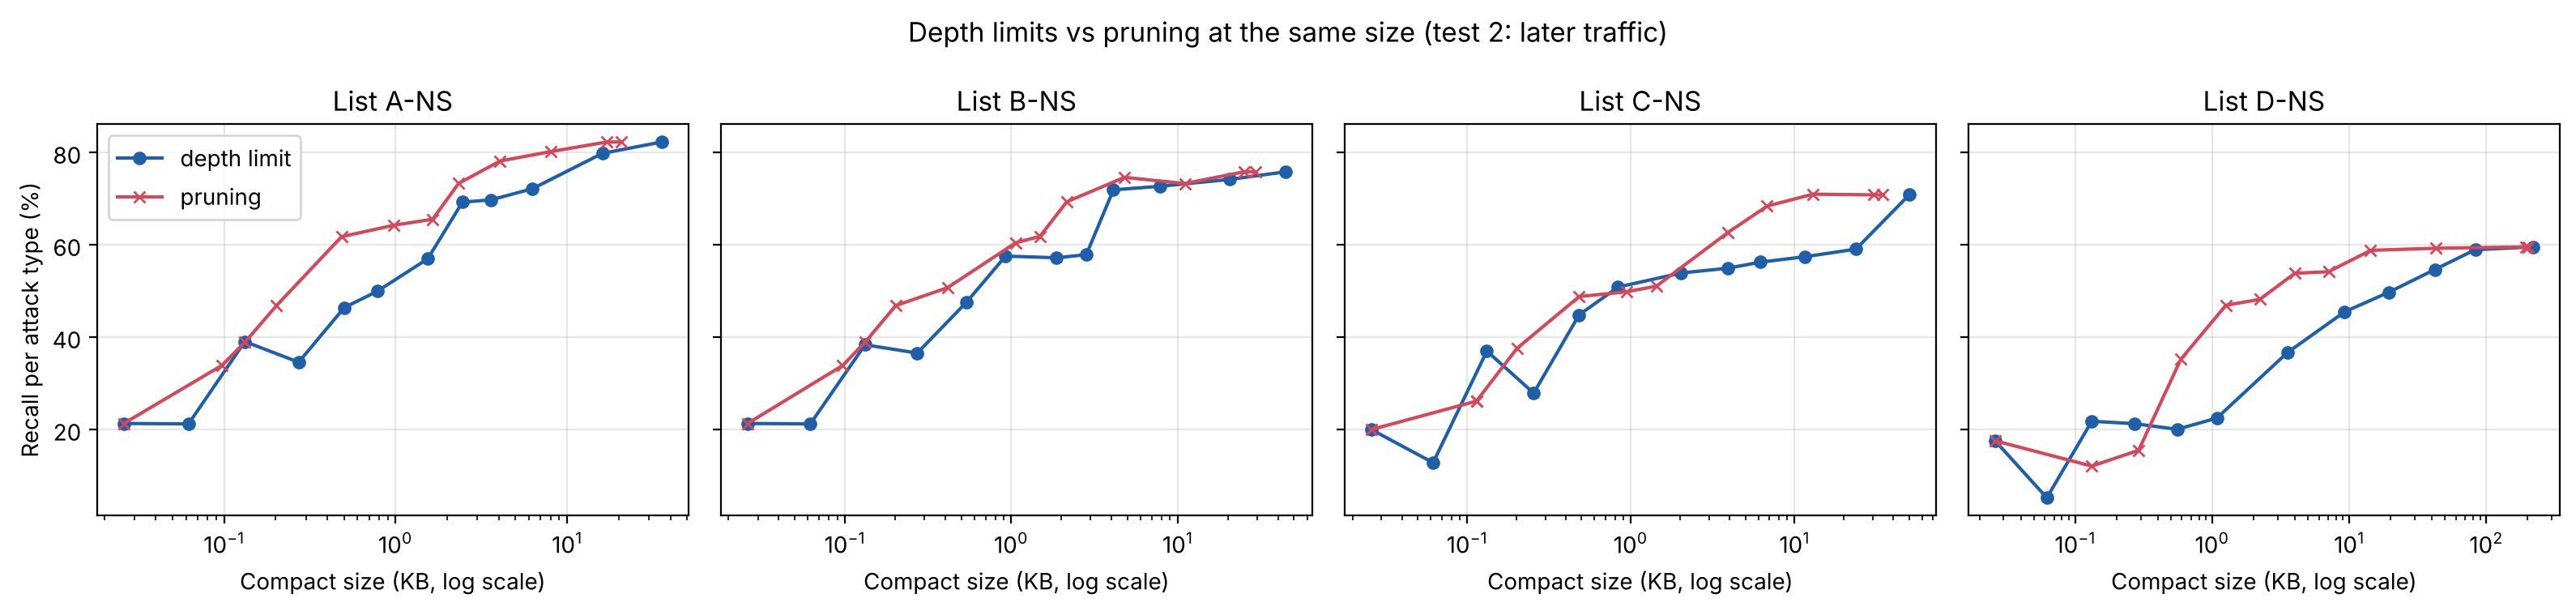

In [11]:
t2 = trees[trees["test"] == "2 later traffic"]
fig, axes = plt.subplots(1, len(LISTS), figsize=(4 * len(LISTS), 3.8), sharey=True)
for ax, l in zip(axes, LISTS):
    for method, marker, colour in [("depth limit", "o", "#1f5fa8"), ("pruning", "x", "#d1495b")]:
        c = t2[(t2["feature_list"] == l) & (t2["method"] == method)].sort_values("nodes")
        ax.plot(c["compact_kb"], c["seen_recall_per_attack_mean"] * 100, marker=marker, ms=5, color=colour, label=method)
    ax.set_xscale("log"); ax.set_xlabel("Compact size (KB, log scale)"); ax.set_title(f"List {l}"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Recall per attack type (%)"); axes[0].legend()
fig.suptitle("Depth limits vs pruning at the same size (test 2: later traffic)")
fig.tight_layout(); fig.savefig(h.FIG_DIR / "fig5_depth_vs_pruning.png", dpi=200); plt.show()

In [12]:
# For every pruned tree: the smallest depth-limited tree that is at least as big, same run and list.
# Does pruning match or beat it?
def pruning_wins(score_column, tests):
    wins = total = 0
    for _, g in trees[trees["test"].isin(tests)].groupby(KEYS):
        d = g[g["method"] == "depth limit"].sort_values("nodes")
        for _, p in g[g["method"] == "pruning"].iterrows():
            bigger = d[d["nodes"] >= p["nodes"]]
            if len(bigger) and not np.isnan(p[score_column]):
                total += 1
                wins += p[score_column] >= bigger.iloc[0][score_column]
    return wins, total

for label, col, tests in [("seen attacks, recall per type (tests 1-2)", "seen_recall_per_attack_mean", ["1 random split", "2 later traffic"]),
                          ("unseen attacks (tests 3-4)", "unseen_recall_per_attack_mean", ["3 new attack", "4 new day"])]:
    wins, total = pruning_wins(col, tests)
    print(f"{label}: pruning matches or beats the depth limit in {wins} of {total} comparisons ({wins / total:.0%})")

seen attacks, recall per type (tests 1-2): pruning matches or beats the depth limit in 77 of 96 comparisons (80%)


unseen attacks (tests 3-4): pruning matches or beats the depth limit in 656 of 864 comparisons (76%)


## What this shows

All numbers are for full-size trees on list A-NS (55 features) unless another list is named.

**1. The headline score depends almost entirely on the test.** The same kind of tree catches
99.2% of attack flows with a random split, 94.7% on later traffic from the same attacks,
55.7% of the flows of an attack type it has never seen, and 7.2% of the attacks on a day it
has never seen. Counting every attack type equally, the four numbers are 86.0%, 82.3%, 32.3%
and 16.4%. Lists B-NS and C-NS are close to A-NS on the first three tests and lower on the
fourth; D-NS (4 features) is worse on the first three.

**2. Unseen attacks are caught only when a close relative was in training.** Kept out of
training, DoS Hulk is still caught 85.8% of the time, Web Attack - XSS 92.9%, Web Attack -
Brute Force 82.5%, DoS slowloris 70.9% and DDoS 63.0%: each has a similar attack (another
flood, another web attack, another slow DoS) left in the training data. Attacks with no
relative are missed almost completely: PortScan 0.2%, FTP-Patator 0.0%, SSH-Patator 0.1%,
Bot 0.0%, Heartbleed 0 of 11.

**3. Even a seen attack can be missed later the same day.** Bot is caught 48.7% of the time
with a random split and **0 of 389** flows in the later-traffic test, on every list. Its
later flows do not look like its earlier ones. A random split hides this completely.

**4. False alarms rise on a new day.** On later traffic from days the tree has seen, the
false-alarm rate is 0.08%. On a day it has never seen it is 0.04% to 3.4% depending on the
day (1.2% on average), and up to 7.7% for list B-NS on Thursday. v1's Friday check found no
such rise, but that was one tree on one afternoon.

**5. A bigger tree buys recall on attacks it has seen, and little else.** For seen attacks,
recall per attack type climbs steadily with depth: 21% at depth 1, 50% at depth 6, 69% at
depth 10, 80% at depth 20 and 82% with no limit. For unseen attack types it stays between
11% and 23% up to depth 10 and reaches 31-33% from depth 12; for the other three lists it
never passes 28% at any depth. Most of the extra nodes are spent on describing the attacks
in the training data more exactly.

**6. Depth limits could not shrink the trees safely; pruning could.** Under the validation
rule, no depth limit was accepted for any list on later traffic: some attack type always
lost more than 1 point. Pruning passed the rule with 77% fewer nodes for A-NS (4,043 to 913
nodes, 35.5 KB to 8.0 KB) and 74% fewer for C-NS, with recall over all attack flows unchanged
(94.7%) and recall per attack type down 2 points (82.3% to 80.2%, almost all of it from 2
fewer of the 7 Infiltration test flows). Across all sizes, a pruned tree matched or beat the
depth-limited tree of at least the same size in 80% of comparisons on seen attacks and 76% on
unseen ones.

**7. Size on a small device.** The full A-NS tree (35.5 KB) no longer fits the 32 KB of an
ATmega328P; the pruned one (8.0 KB) does. Every tree fits the 512 KB of an STM32F401. v1's
trees were smaller (7 to 13 KB) because they used the shortcut features and one day of data.

## What this cannot show

- Tests 1 and 2 are **one split each** (seed 42 and one cut by time), not five as in v1.
  Tests 3 and 4 are averages over 14 and 5 runs.
- "Time" is the row order of the public CSV files, which have no timestamp column.
- Three attack types are tiny (Heartbleed 11 flows, Web Attack - Sql Injection 21,
  Infiltration 36), so their recall moves in big steps.
- Depth-limited trees were made by cutting the full tree. Notebook 03 measured that this
  agrees with re-training on at least 99.9% of test flows at the depths it checked, but they
  are not always the identical tree.
- In tests 3 and 4 the tree size is chosen on validation rows that contain only seen attacks.
- All five days come from **one lab network in one week**. A new day here is still the same
  network, so a different network is likely to be harder. The feature lists were chosen on
  Wednesday's data in v1. CICIDS2017 also has known labelling errors (Engelen et al., 2021).